In [1]:
!conda info


     active environment : singlecell
    active env location : /home/cpc/srsridatta.prakki/sw/miniconda3/envs/singlecell
            shell level : 3
       user config file : /home/cpc/srsridatta.prakki/.condarc
 populated config files : /home/cpc/srsridatta.prakki/.condarc
          conda version : 23.5.2
    conda-build version : not installed
         python version : 3.11.4.final.0
       virtual packages : __archspec=1=x86_64
                          __cuda=13.3=0
                          __glibc=2.39=0
                          __linux=6.12.0=0
                          __unix=0=0
       base environment : /home/cpc/srsridatta.prakki/sw/miniconda3  (writable)
      conda av data dir : /home/cpc/srsridatta.prakki/sw/miniconda3/etc/conda
  conda av metadata url : None
           channel URLs : https://repo.anaconda.com/pkgs/main/linux-64
                          https://repo.anaconda.com/pkgs/main/noarch
                          https://repo.anaconda.com/pkgs/r/linux-64
      

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Pseudobulk DE - Reichart 2022 heart fibroblasts (CELLxGENE Census)
# One "# %%" block = one Jupyter cell. Run top to bottom.
# pip install "cellxgene-census==1.18.0" "pydeseq2>=0.5.2" matplotlib

In [4]:
# %% 1. Imports and settings
import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import anndata as ad
import cellxgene_census
from formulaic import model_matrix
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

os.makedirs("data", exist_ok=True)
H5AD = "data/reichart_fibroblasts.h5ad"
MIN_CELLS = 20
ALPHA = 0.05

In [5]:
# %% 2. Find the Reichart dataset in Census
census = cellxgene_census.open_soma(census_version="stable")

The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


In [7]:
census

<Collection 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/' (open for 'r') (3 items)
    'census_data': 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_data' (unopened)
    'census_info': Collection 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_info' (open for 'r') (4 items)
        'datasets': DataFrame 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_info/datasets' (open for 'r')
        'organisms': 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_info/organisms' (unopened)
        'summary': 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_info/summary' (unopened)
        'summary_cell_counts': 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_info/summary_cell_counts' (unopened)
    'census_spatial_sequencing': 's3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/soma/census_spatial_sequencing

In [6]:
datasets = census["census_info"]["datasets"].read().concat().to_pandas()

In [8]:
datasets

,soma_joinid,citation,collection_id,collection_name,collection_doi,collection_doi_label,dataset_id,dataset_version_id,dataset_title,dataset_h5ad_path,dataset_total_cell_count
0,0,Publication: https://doi.org/10.1016/j.isci.20...,8e880741-bf9a-4c8e-9227-934204631d2a,High Resolution Slide-seqV2 Spatial Transcript...,10.1016/j.isci.2022.104097,Marshall et al. (2022) iScience,4eb29386-de81-452f-b3c0-e00844e8c7fd,66699060-0389-4fbd-b3a5-196b3b4e32d6,Spatial transcriptomics in mouse: Puck_191112_05,4eb29386-de81-452f-b3c0-e00844e8c7fd.h5ad,10888
1,1,Publication: https://doi.org/10.1016/j.isci.20...,8e880741-bf9a-4c8e-9227-934204631d2a,High Resolution Slide-seqV2 Spatial Transcript...,10.1016/j.isci.2022.104097,Marshall et al. (2022) iScience,78d59e4a-82eb-4a61-a1dc-da974d7ea54b,f64950a2-a3c8-490a-8431-7121eeb4f5f4,Spatial transcriptomics in mouse: Puck_191112_08,78d59e4a-82eb-4a61-a1dc-da974d7ea54b.h5ad,10250
2,2,Publication: https://doi.org/10.1016/j.isci.20...,8e880741-bf9a-4c8e-9227-934204631d2a,High Resolution Slide-seqV2 Spatial Transcript...,10.1016/j.isci.2022.104097,Marshall et al. (2022) iScience,add5eb84-5fc9-4f01-982e-a346dd42ee82,781a724a-b0f5-46c4-9a13-e6293ef4364f,Spatial transcriptomics in mouse: Puck_191109_20,add5eb84-5fc9-4f01-982e-a346dd42ee82.h5ad,12906
3,3,Publication: https://doi.org/10.1016/j.isci.20...,8e880741-bf9a-4c8e-9227-934204631d2a,High Resolution Slide-seqV2 Spatial Transcript...,10.1016/j.isci.2022.104097,Marshall et al. (2022) iScience,b020294c-ab82-4547-b5a7-63d8ffa575ed,96a79598-297b-4ade-a6c1-a431ab243548,Spatial transcriptomics in mouse: Puck_191112_13,b020294c-ab82-4547-b5a7-63d8ffa575ed.h5ad,15161
4,4,Publication: https://doi.org/10.1038/s41591-02...,a96133de-e951-4e2d-ace6-59db8b3bfb1d,HTAN/HTAPP Broad - Spatio-molecular dissection...,10.1038/s41591-024-03215-z,Klughammer et al. (2024) Nat Med,d7476ae2-e320-4703-8304-da5c42627e71,ac9fe945-6784-48fa-a2d5-a8646196d37e,HTAPP-330-SMP-1082 scRNA-seq,d7476ae2-e320-4703-8304-da5c42627e71.h5ad,565
...,...,...,...,...,...,...,...,...,...,...,...
1840,1840,Publication: https://doi.org/10.1038/s41586-02...,45d5d2c3-bc28-4814-aed6-0bb6f0e11c82,A single-cell transcriptional timelapse of mou...,10.1038/s41586-024-07069-w,Qiu et al. (2024) Nature,dcfa2614-7ca7-4d82-814c-350626eccb26,ca20ef35-13c0-4850-bec4-ba00e6bbd6f9,Major cell cluster: Mesoderm,dcfa2614-7ca7-4d82-814c-350626eccb26.h5ad,3267338
1841,1841,Publication: https://doi.org/10.1126/science.a...,e5f58829-1a66-40b5-a624-9046778e74f5,Tabula Sapiens,10.1126/science.abl4896,The Tabula Sapiens Consortium* et al. (2022) S...,53d208b0-2cfd-4366-9866-c3c6114081bc,5a495302-b7cd-4bf9-853e-95627b00bb03,Tabula Sapiens - All Cells,53d208b0-2cfd-4366-9866-c3c6114081bc.h5ad,1136218
1842,1842,Publication: https://doi.org/10.1038/s41586-02...,45d5d2c3-bc28-4814-aed6-0bb6f0e11c82,A single-cell transcriptional timelapse of mou...,10.1038/s41586-024-07069-w,Qiu et al. (2024) Nature,dcfd4feb-18a3-4b30-81d7-1b0c544a8ab3,a5a85963-8004-41a1-8eb5-ca65266d89c3,Whole dataset: Raw counts only,dcfd4feb-18a3-4b30-81d7-1b0c544a8ab3.h5ad,11441407
1843,1843,Publication: https://doi.org/10.1038/s41593-02...,1ca90a2d-2943-483d-b678-b809bf464c30,SEA-AD: Seattle Alzheimer’s Disease Brain Cell...,10.1038/s41593-024-01774-5,Gabitto et al. (2024) Nat Neurosci,c2876b1b-06d8-4d96-a56b-5304f815b99a,92b37feb-aa2c-40d7-bd90-0a9b5ddb3b27,Whole Taxonomy - MTG: Seattle Alzheimer's Dise...,c2876b1b-06d8-4d96-a56b-5304f815b99a.h5ad,1378211


In [9]:
hits = datasets[datasets["collection_name"].str.contains("pathogenic variants", case=False)]

In [10]:
hits

,soma_joinid,citation,collection_id,collection_name,collection_doi,collection_doi_label,dataset_id,dataset_version_id,dataset_title,dataset_h5ad_path,dataset_total_cell_count
308,308,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,bdf69f8d-5a96-4d6f-a9f5-9ee0e33597b7,bfed5201-acc3-433c-b037-f84a04d93c5c,DCM/ACM heart cell atlas: Adipocytes,bdf69f8d-5a96-4d6f-a9f5-9ee0e33597b7.h5ad,2576
487,487,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,0fdb6122-4600-40f0-a703-2da47cc7080d,ea2c22a3-cdfc-4de5-ada3-75d20a6d4c79,DCM/ACM heart cell atlas: Lymphoids,0fdb6122-4600-40f0-a703-2da47cc7080d.h5ad,16878
681,681,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,83b5e943-a1d5-4164-b3f2-f7a37f01b524,eed2c5d7-bfe6-4d76-81e6-f9184dfbaad3,DCM/ACM heart cell atlas: Neuronal cells,83b5e943-a1d5-4164-b3f2-f7a37f01b524.h5ad,7999
1398,1398,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,9434b020-de42-43eb-bcc4-542b2be69015,bab99329-f745-4789-91b8-b7c19fa38fe7,DCM/ACM heart cell atlas: Macrophages,9434b020-de42-43eb-bcc4-542b2be69015.h5ad,59217
1407,1407,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,ed2b673b-0279-454a-998c-3eec361edf54,3edbe923-e507-4527-84bb-421842df7781,DCM/ACM heart cell atlas: Fibroblasts,ed2b673b-0279-454a-998c-3eec361edf54.h5ad,142816
1415,1415,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,1062c0f2-2a44-4cf9-a7c8-b5ed58b4728d,fb934f50-3174-4fea-9dfa-2d1d9e80f650,DCM/ACM heart cell atlas: Endothelial cells,1062c0f2-2a44-4cf9-a7c8-b5ed58b4728d.h5ad,115548
1680,1680,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,f7995301-7551-4e1d-8396-ffe3c9497ace,4e0a1252-c993-42ae-a0a8-e6cf3f02bfdb,DCM/ACM heart cell atlas: Cardiomyocytes,f7995301-7551-4e1d-8396-ffe3c9497ace.h5ad,311418
1756,1756,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,1252c5fb-945f-42d6-b1a8-8a3bd864384b,ca05a5f1-7db3-4c66-86f0-4d41563b27c3,DCM/ACM heart cell atlas: Mural cells,1252c5fb-945f-42d6-b1a8-8a3bd864384b.h5ad,170281
1769,1769,Publication: https://doi.org/10.1126/science.a...,e75342a8-0f3b-4ec5-8ee1-245a23e0f7cb,Pathogenic variants damage cell composition an...,10.1126/science.abo1984,Reichart et al. (2022) Science,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,9de5d490-b221-4529-875d-91d8b5c321e2,DCM/ACM heart cell atlas: All cells,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039.h5ad,881081


In [11]:
print(hits[["dataset_title", "dataset_id", "dataset_total_cell_count"]])

                                    dataset_title  \
308          DCM/ACM heart cell atlas: Adipocytes   
487           DCM/ACM heart cell atlas: Lymphoids   
681      DCM/ACM heart cell atlas: Neuronal cells   
1398        DCM/ACM heart cell atlas: Macrophages   
1407        DCM/ACM heart cell atlas: Fibroblasts   
1415  DCM/ACM heart cell atlas: Endothelial cells   
1680     DCM/ACM heart cell atlas: Cardiomyocytes   
1756        DCM/ACM heart cell atlas: Mural cells   
1769          DCM/ACM heart cell atlas: All cells   

                                dataset_id  dataset_total_cell_count  
308   bdf69f8d-5a96-4d6f-a9f5-9ee0e33597b7                      2576  
487   0fdb6122-4600-40f0-a703-2da47cc7080d                     16878  
681   83b5e943-a1d5-4164-b3f2-f7a37f01b524                      7999  
1398  9434b020-de42-43eb-bcc4-542b2be69015                     59217  
1407  ed2b673b-0279-454a-998c-3eec361edf54                    142816  
1415  1062c0f2-2a44-4cf9-a7c8-b5ed58b4728d 

In [12]:
dataset_ids = hits["dataset_id"].tolist()

In [13]:
dataset_ids

['bdf69f8d-5a96-4d6f-a9f5-9ee0e33597b7',
 '0fdb6122-4600-40f0-a703-2da47cc7080d',
 '83b5e943-a1d5-4164-b3f2-f7a37f01b524',
 '9434b020-de42-43eb-bcc4-542b2be69015',
 'ed2b673b-0279-454a-998c-3eec361edf54',
 '1062c0f2-2a44-4cf9-a7c8-b5ed58b4728d',
 'f7995301-7551-4e1d-8396-ffe3c9497ace',
 '1252c5fb-945f-42d6-b1a8-8a3bd864384b',
 '65badd7a-9262-4fd1-9ce2-eb5dc0ca8039']

In [14]:
base_filter = f"dataset_id in {dataset_ids} and is_primary_data == True"

In [16]:
base_filter

"dataset_id in ['bdf69f8d-5a96-4d6f-a9f5-9ee0e33597b7', '0fdb6122-4600-40f0-a703-2da47cc7080d', '83b5e943-a1d5-4164-b3f2-f7a37f01b524', '9434b020-de42-43eb-bcc4-542b2be69015', 'ed2b673b-0279-454a-998c-3eec361edf54', '1062c0f2-2a44-4cf9-a7c8-b5ed58b4728d', 'f7995301-7551-4e1d-8396-ffe3c9497ace', '1252c5fb-945f-42d6-b1a8-8a3bd864384b', '65badd7a-9262-4fd1-9ce2-eb5dc0ca8039'] and is_primary_data == True"

In [17]:
# %% 3. Read cell metadata only (small), find the fibroblast labels
cols = ["donor_id", "cell_type", "tissue", "disease", "sex", "development_stage", "assay"]
obs_all = census["census_data"]["homo_sapiens"].obs.read(
    value_filter=base_filter, column_names=cols).concat().to_pandas()

In [18]:
print(obs_all["cell_type"].value_counts())
print(obs_all["tissue"].value_counts())
print(obs_all["disease"].value_counts())

cell_type
cardiac muscle cell                     197321
mural cell                              128390
fibroblast of cardiac tissue            118389
endothelial cell                        103157
myeloid cell                             52583
                                         ...  
endothelial tip cell                         0
enteric neuron                               0
enteric smooth muscle cell                   0
enterochromaffin-like cell                   0
endothelial cell of lymphatic vessel         0
Name: count, Length: 898, dtype: int64
tissue
heart left ventricle             310880
interventricular septum          177570
heart right ventricle            177505
peripheral zone of prostate           0
peripheral region of retina           0
                                  ...  
epithelium of trachea                 0
epithelium of stomach                 0
epithelium of small intestine         0
epithelium of rectum                  0
eyelid                     

In [19]:
all_types = obs_all["cell_type"].astype(str).unique()
fib_labels = [c for c in all_types if "fibroblast" in c.lower()]
print("Fibroblast labels:", fib_labels)

Fibroblast labels: ['fibroblast of cardiac tissue']


In [20]:
# %% 4. Download raw counts for fibroblasts only (first run only), then load
if not os.path.exists(H5AD):
    adata = cellxgene_census.get_anndata(
        census,
        organism="Homo sapiens",
        X_name="raw",
        obs_value_filter=f"{base_filter} and cell_type in {fib_labels}",
        obs_column_names=cols,
        var_column_names=["feature_id", "feature_name"],
    )
    adata.write_h5ad(H5AD, compression="gzip")
census.close()

In [21]:
adata = ad.read_h5ad(H5AD)
adata.var_names = adata.var["feature_id"].astype(str)
symbols = adata.var["feature_name"].astype(str)
print(adata)

AnnData object with n_obs × n_vars = 118389 × 61497
    obs: 'donor_id', 'cell_type', 'tissue', 'disease', 'sex', 'development_stage', 'assay', 'dataset_id', 'is_primary_data'
    var: 'feature_id', 'feature_name'


In [22]:
# %% 5. Check: counts must be raw integers (never pseudobulk normalized data)
X = sp.csr_matrix(adata.X)
print("All integers:", np.allclose(X.data, np.round(X.data)))

All integers: True


In [23]:
adata.obs

,donor_id,cell_type,tissue,disease,sex,development_stage,assay,dataset_id,is_primary_data
0,DP2,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
1,DP2,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
2,DP2,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
3,DP2,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
4,DP2,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
...,...,...,...,...,...,...,...,...,...
118384,IC_H04,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,seventh decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
118385,IC_H04,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,seventh decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
118386,IC_H04,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,seventh decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True
118387,IC_H04,fibroblast of cardiac tissue,heart right ventricle,dilated cardiomyopathy,female,seventh decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,True


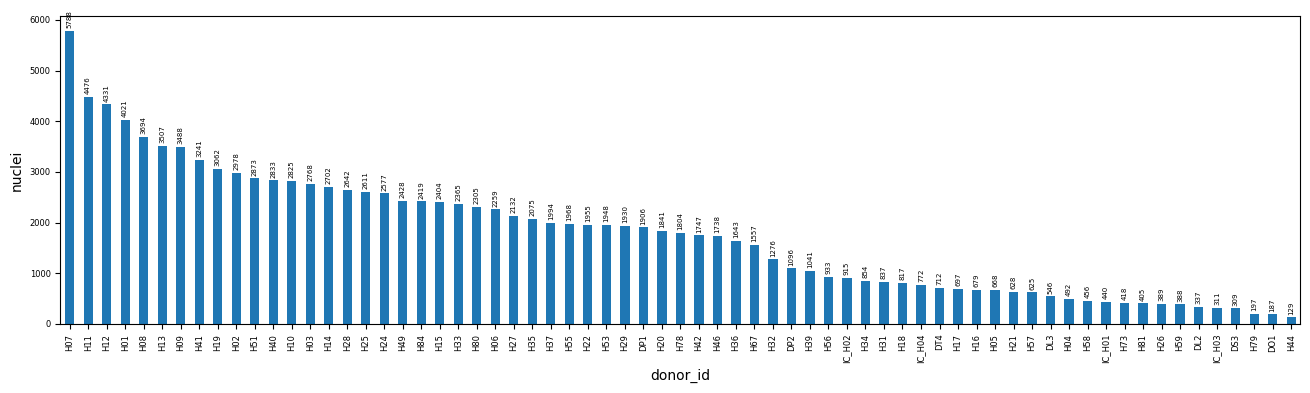

In [25]:
import matplotlib.pyplot as plt
counts = adata.obs["donor_id"].astype(str).value_counts()
ax = counts.plot(kind="bar", figsize=(16, 4), fontsize=6)
ax.bar_label(ax.containers[0], fontsize=5, rotation=90, padding=2)
plt.ylabel("nuclei")
plt.show()

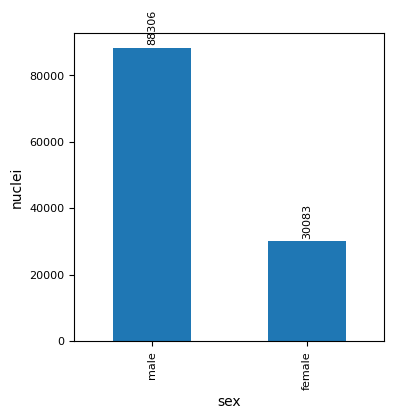

In [30]:
import matplotlib.pyplot as plt
counts = adata.obs["sex"].astype(str).value_counts()
ax = counts.plot(kind="bar", figsize=(4, 4), fontsize=8)
ax.bar_label(ax.containers[0], fontsize=8, rotation=90, padding=2)
plt.ylabel("nuclei")
plt.show()

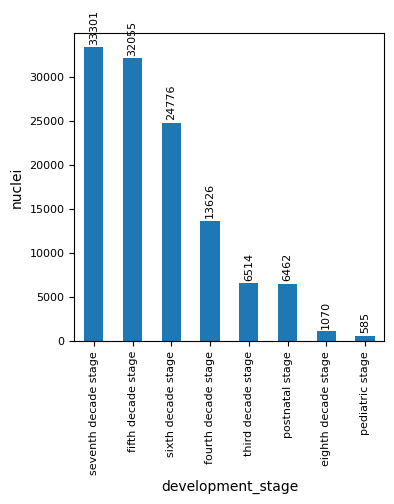

In [31]:
import matplotlib.pyplot as plt
counts = adata.obs["development_stage"].astype(str).value_counts()
ax = counts.plot(kind="bar", figsize=(4, 4), fontsize=8)
ax.bar_label(ax.containers[0], fontsize=8, rotation=90, padding=2)
plt.ylabel("nuclei")
plt.show()

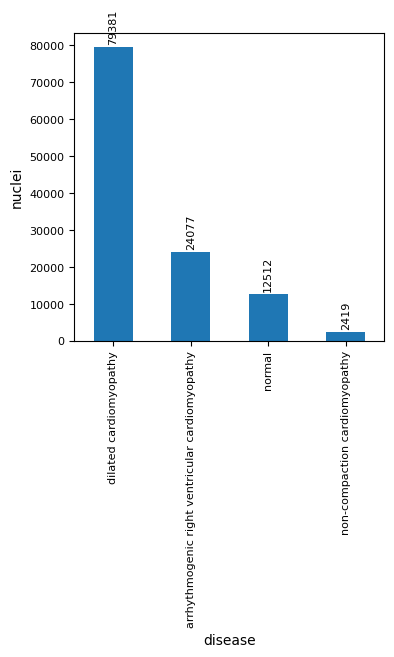

In [32]:
import matplotlib.pyplot as plt
counts = adata.obs["disease"].astype(str).value_counts()
ax = counts.plot(kind="bar", figsize=(4, 4), fontsize=8)
ax.bar_label(ax.containers[0], fontsize=8, rotation=90, padding=2)
plt.ylabel("nuclei")
plt.show()

In [33]:
# 1. Keep normal + DCM, left ventricle only
adata_norm_dc = adata[adata.obs["disease"].isin(["normal", "dilated cardiomyopathy"])
            & adata.obs["tissue"].astype(str).str.contains("left ventricle")]

In [34]:
adata_norm_dc

View of AnnData object with n_obs × n_vars = 41660 × 61497
    obs: 'donor_id', 'cell_type', 'tissue', 'disease', 'sex', 'development_stage', 'assay', 'dataset_id', 'is_primary_data'
    var: 'feature_id', 'feature_name'

In [36]:
import scanpy as sc
# 2. Pseudobulk: sum raw counts per donor
pb = sc.get.aggregate(adata_norm_dc, by="donor_id", func="sum")

In [37]:
pb

AnnData object with n_obs × n_vars = 56 × 61497
    obs: 'donor_id'
    var: 'feature_id', 'feature_name'
    layers: 'sum'

In [39]:
pb.obs.head()

,donor_id
DL2,DL2
DL3,DL3
DO1,DO1
DP1,DP1
DP2,DP2


In [40]:
pb.var.head()

,feature_id,feature_name
feature_id,,
ENSG00000237491,ENSG00000237491,LINC01409
ENSG00000188976,ENSG00000188976,NOC2L
ENSG00000187642,ENSG00000187642,PERM1
ENSG00000272512,ENSG00000272512,ENSG00000272512
ENSG00000188290,ENSG00000188290,HES4


In [41]:
counts = pb.to_df(layer="sum").astype(int)

In [49]:
counts

feature_name,LINC01409,NOC2L,PERM1,ENSG00000272512,HES4,ISG15,AGRN,RNF223,C1orf159,TNFRSF18,...,ENSG00000290852,XKRY,XKRYP7,BCORP1,TXLNGY,RBMY2FP,ENSG00000290348,GOLGA2P2Y,CD99P1,ELOCP24
DL2,56,18,3,1,57,7,3,0,26,0,...,0,0,0,0,0,0,0,0,0,0
DL3,74,64,0,0,33,10,7,0,41,0,...,0,0,0,0,0,0,0,0,0,0
DO1,57,31,0,0,18,3,3,0,38,2,...,0,0,0,0,0,0,0,0,0,0
DP1,229,96,6,85,512,40,44,0,115,0,...,0,0,0,0,0,0,0,0,0,0
DP2,92,35,2,4,132,7,5,0,44,0,...,0,0,0,0,0,0,0,0,0,0
DS3,38,31,1,1,57,9,5,0,14,0,...,0,0,0,0,0,0,0,0,0,0
DT4,88,33,2,3,69,11,1,0,33,0,...,0,0,0,0,0,0,0,0,0,0
H01,229,60,3,23,159,26,13,0,90,0,...,0,0,0,0,0,0,0,0,0,0
H02,141,93,1,9,260,15,18,0,65,0,...,0,0,0,0,0,0,0,0,0,0
H03,113,57,7,16,102,16,15,0,55,0,...,0,0,0,0,0,0,0,0,0,0


In [43]:
counts.head()

feature_id,ENSG00000237491,ENSG00000188976,ENSG00000187642,ENSG00000272512,ENSG00000188290,ENSG00000187608,ENSG00000188157,ENSG00000237330,ENSG00000131591,ENSG00000186891,...,ENSG00000290852,ENSG00000290724,ENSG00000290725,ENSG00000291031,ENSG00000291033,ENSG00000290336,ENSG00000290348,ENSG00000291016,ENSG00000292362,ENSG00000292367
DL2,56,18,3,1,57,7,3,0,26,0,...,0,0,0,0,0,0,0,0,0,0
DL3,74,64,0,0,33,10,7,0,41,0,...,0,0,0,0,0,0,0,0,0,0
DO1,57,31,0,0,18,3,3,0,38,2,...,0,0,0,0,0,0,0,0,0,0
DP1,229,96,6,85,512,40,44,0,115,0,...,0,0,0,0,0,0,0,0,0,0
DP2,92,35,2,4,132,7,5,0,44,0,...,0,0,0,0,0,0,0,0,0,0


In [44]:
counts.columns = pb.var.loc[counts.columns, "feature_name"].astype(str)

In [45]:
counts.head()

feature_name,LINC01409,NOC2L,PERM1,ENSG00000272512,HES4,ISG15,AGRN,RNF223,C1orf159,TNFRSF18,...,ENSG00000290852,XKRY,XKRYP7,BCORP1,TXLNGY,RBMY2FP,ENSG00000290348,GOLGA2P2Y,CD99P1,ELOCP24
DL2,56,18,3,1,57,7,3,0,26,0,...,0,0,0,0,0,0,0,0,0,0
DL3,74,64,0,0,33,10,7,0,41,0,...,0,0,0,0,0,0,0,0,0,0
DO1,57,31,0,0,18,3,3,0,38,2,...,0,0,0,0,0,0,0,0,0,0
DP1,229,96,6,85,512,40,44,0,115,0,...,0,0,0,0,0,0,0,0,0,0
DP2,92,35,2,4,132,7,5,0,44,0,...,0,0,0,0,0,0,0,0,0,0


In [47]:
(counts >= 10).sum()

feature_name
LINC01409          55
NOC2L              55
PERM1               0
ENSG00000272512    24
HES4               55
                   ..
RBMY2FP             0
ENSG00000290348     0
GOLGA2P2Y           0
CD99P1              0
ELOCP24             0
Length: 61497, dtype: int64

In [50]:
counts = counts.loc[:, (counts >= 10).sum() >= 5]   # drop low-count genes

In [52]:
counts

feature_name,LINC01409,NOC2L,ENSG00000272512,HES4,ISG15,AGRN,C1orf159,SDF4,B3GALT6,UBE2J2,...,LINC02478,ENSG00000285382,ENSG00000285404,ENSG00000285407,ENSG00000285413,ENSG00000285444,ENSG00000285446,ENSG00000285454,C4orf36,ENSG00000285471
DL2,56,18,1,57,7,3,26,44,9,29,...,4,1,2,0,0,2,0,2,9,2
DL3,74,64,0,33,10,7,41,98,16,58,...,15,5,1,4,3,2,3,5,40,2
DO1,57,31,0,18,3,3,38,39,4,47,...,3,6,4,3,0,1,2,4,16,3
DP1,229,96,85,512,40,44,115,69,2,118,...,6,47,17,6,6,7,2,4,34,5
DP2,92,35,4,132,7,5,44,28,1,48,...,12,28,4,10,1,7,7,4,29,2
DS3,38,31,1,57,9,5,14,17,3,25,...,8,14,5,11,1,3,3,4,12,2
DT4,88,33,3,69,11,1,33,14,0,40,...,16,17,3,9,2,8,4,8,17,4
H01,229,60,23,159,26,13,90,100,9,98,...,35,21,24,13,18,14,6,7,65,4
H02,141,93,9,260,15,18,65,75,12,110,...,17,31,12,14,8,7,6,11,34,10
H03,113,57,16,102,16,15,55,43,2,76,...,19,32,10,5,11,6,5,1,30,0


In [51]:
(counts >= 10).sum()

feature_name
LINC01409          55
NOC2L              55
ENSG00000272512    24
HES4               55
ISG15              29
                   ..
ENSG00000285444    12
ENSG00000285446    12
ENSG00000285454     8
C4orf36            49
ENSG00000285471     7
Length: 15742, dtype: int64

In [53]:
# 3. One row of metadata per donor
meta = adata_norm_dc.obs[["donor_id", "disease"]].astype(str).drop_duplicates().set_index("donor_id").loc[counts.index]


In [59]:
meta = adata_norm_dc.obs[["donor_id", "disease", "sex", "development_stage", "assay", "dataset_id"]].astype(str).drop_duplicates().set_index("donor_id").loc[counts.index]
meta["disease"] = meta["disease"].replace({"dilated cardiomyopathy": "DCM"})
print(meta.nunique())

disease              2
sex                  2
development_stage    8
assay                1
dataset_id           1
dtype: int64


In [60]:
meta

,disease,sex,development_stage,assay,dataset_id
DL2,DCM,male,eighth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
DL3,DCM,male,eighth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
DO1,DCM,male,eighth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
DP1,DCM,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
DP2,DCM,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
DS3,DCM,male,sixth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
DT4,DCM,male,seventh decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
H01,DCM,male,sixth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
H02,DCM,male,sixth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039
H03,DCM,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039


The output tells you what to keep:

assay = 1 and dataset_id = 1: every donor has the same value, so there's no batch to adjust for. Drop both.
sex = 2: keep it as a covariate.
development_stage = 8: that's age, but stored as text, and 8 distinct values across your donors suggests age groups rather than exact ages. CELLxGENE often records age as decades, such as "sixth decade human stage" for ages 50–59.

Convert it to a number. Using 8 categories would cost 7 degrees of freedom, so treat age as one continuous number instead. Map each decade to its midpoint:

In [61]:
decades = {"second": 15, "third": 25, "fourth": 35, "fifth": 45,
           "sixth": 55, "seventh": 65, "eighth": 75, "ninth": 85}
meta["age"] = meta["development_stage"].str.extract(r"(\w+) decade")[0].map(decades)
print(meta[["development_stage", "age"]].drop_duplicates().sort_values("age"))

        development_stage   age
H16    third decade stage  25.0
H06   fourth decade stage  35.0
DP1    fifth decade stage  45.0
DS3    sixth decade stage  55.0
DT4  seventh decade stage  65.0
DL2   eighth decade stage  75.0
H59       pediatric stage   NaN
H73       postnatal stage   NaN


In [62]:
# Drop the pediatric and postnatal stage donors, these are children we dont have exact age

In [63]:
meta = meta[meta["age"].notna()]
counts = counts.loc[meta.index]
counts = counts.loc[:, (counts >= 10).sum() >= 5]
meta["age_z"] = (meta["age"] - meta["age"].mean()) / meta["age"].std()
print(meta["disease"].value_counts())

disease
DCM       44
normal     6
Name: count, dtype: int64


## Covariate

A covariate is any extra variable you put in the model besides the one you're testing. You include it because it also affects gene expression.

In ~ sex + disease:

disease is the variable of interest, the one you want to test.
sex is a covariate. It also changes gene expression, so you let the model account for it.

## Confounder

Yes, that's it, with one word to adjust: **"is associated with"** is more accurate than "identifies with."

A confounder **leans toward** one condition; it doesn't have to match it exactly. In the example, DCM was *mostly* men, not *only* men. That partial overlap is enough to create a fake effect, and it's also why the model can still separate the two. The model compares the few women with DCM against the few men in the normal group, and from those mismatched cases it can work out which effect belongs to sex and which to disease.

The case where it **fully** identifies with a condition is different:

|  | Women | Men |
|---|---|---|
| Normal | 10 | 0 |
| DCM | 0 | 10 |

Now sex and disease are perfectly mixed up. Every difference could be sex, or disease, or both, and no model can separate them, because there are no mismatched cases to learn from. If you put both in the design, PyDESeq2 will fail with a "not full rank" error. This is called **complete confounding**, and statistics can't fix it; only a better study design can.

To summarize:
- **Partly associated:** a confounder. Add it to the model and the problem is solved.
- **Fully associated:** complete confounding. You can't separate the two effects, and you have to report that as a limitation.

In [64]:
meta

,disease,sex,development_stage,assay,dataset_id,age,age_z
DL2,DCM,male,eighth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,75.0,1.871350
DL3,DCM,male,eighth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,75.0,1.871350
DO1,DCM,male,eighth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,75.0,1.871350
DP1,DCM,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,45.0,-0.255184
DP2,DCM,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,45.0,-0.255184
DS3,DCM,male,sixth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,55.0,0.453661
DT4,DCM,male,seventh decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,65.0,1.162506
H01,DCM,male,sixth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,55.0,0.453661
H02,DCM,male,sixth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,55.0,0.453661
H03,DCM,female,fifth decade stage,10x 3' v3,65badd7a-9262-4fd1-9ce2-eb5dc0ca8039,45.0,-0.255184


## No covariates

In [66]:
# 4. DESeq2
# dds = DeseqDataSet(counts=counts, metadata=meta, design="~ donor_id + condition") # if paired

dds_no_covariates = DeseqDataSet(counts=counts, metadata=meta, design="~ disease")
dds_no_covariates.deseq2()
stats_no_covariates = DeseqStats(dds_no_covariates, contrast=["disease", "DCM", "normal"])
stats_no_covariates.summary()
results_no_covariates = stats_no_covariates.results_df

print("DE genes (padj < 0.05):", (results_no_covariates["padj"] < 0.05).sum())

sex_genes = ["XIST", "TSIX", "RPS4Y1", "DDX3Y", "UTY", "KDM5D", "EIF1AY", "USP9Y"]
print(results_no_covariates.loc[results_no_covariates.index.isin(sex_genes), ["log2FoldChange", "padj"]])

Fitting size factors...


Using None as control genes, passed at DeseqDataSet initialization


... done in 0.27 seconds.

Fitting dispersions...
... done in 1.83 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 2.01 seconds.

Fitting LFCs...
... done in 3.10 seconds.

Calculating cook's distance...
... done in 0.07 seconds.

Replacing 23 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                
LINC01409         89.425821       -0.216784  0.183089 -1.184039  0.236398   
NOC2L             60.833510       -0.794067  0.200270 -3.964987  0.000073   
ENSG00000272512   10.519448       -0.801691  0.544566 -1.472163  0.140977   
HES4             126.168222       -0.327225  0.279484 -1.170819  0.241672   
ISG15             11.151627       -0.526393  0.271043 -1.942102  0.052125   
...                     ...             ...       ...       ...       ...   
ENSG00000285444    6.566612        0.307080  0.315804  0.972376  0.330863   
ENSG00000285446    5.845503        0.257531  0.356102  0.723196  0.469559   
ENSG00000285454    4.692762       -0.171643  0.317042 -0.541388  0.588240   
C4orf36           25.949179       -0.051174  0.234117 -0.218582  0.826976   
ENSG00000285471 

... done in 1.92 seconds.



## Sex as covariate

In [67]:
dds_with_sex = DeseqDataSet(counts=counts, metadata=meta, design="~ sex + disease")
dds_with_sex.deseq2()
stats_with_sex = DeseqStats(dds_with_sex, contrast=["disease", "DCM", "normal"])
stats_with_sex.summary()
results_with_sex = stats_with_sex.results_df

print("DE genes (padj < 0.05):", (results_with_sex["padj"] < 0.05).sum())
print(results_with_sex.loc[results_with_sex.index.isin(sex_genes), ["log2FoldChange", "padj"]])

Fitting size factors...
... done in 0.02 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.79 seconds.

Fitting dispersion trend curve...
... done in 0.19 seconds.

Fitting MAP dispersions...
... done in 2.00 seconds.

Fitting LFCs...
... done in 2.18 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 25 outlier genes.

Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                
LINC01409         89.425821       -0.225960  0.184865 -1.222295  0.221596   
NOC2L             60.833510       -0.763439  0.199834 -3.820370  0.000133   
ENSG00000272512   10.519448       -0.989915  0.539657 -1.834342  0.066603   
HES4             126.168222       -0.352914  0.281628 -1.253121  0.210162   
ISG15             11.151627       -0.570378  0.253298 -2.251802  0.024335   
...                     ...             ...       ...       ...       ...   
ENSG00000285444    6.566612        0.302952  0.314563  0.963086  0.335504   
ENSG00000285446    5.845503        0.249930  0.360059  0.694135  0.487598   
ENSG00000285454    4.692762       -0.169282  0.319605 -0.529660  0.596348   
C4orf36           25.949179       -0.053247  0.235382 -0.226216  0.821033   
ENSG00000285471 

... done in 1.89 seconds.



## Age as covariate

In [68]:
dds_with_age = DeseqDataSet(counts=counts, metadata=meta, design="~ age_z + disease")
dds_with_age.deseq2()
stats_with_age = DeseqStats(dds_with_age, contrast=["disease", "DCM", "normal"])
stats_with_age.summary()
results_with_age = stats_with_age.results_df

print("DE genes (padj < 0.05):", (results_with_age["padj"] < 0.05).sum())

Fitting size factors...
... done in 0.02 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.00 seconds.

Fitting dispersion trend curve...
... done in 0.19 seconds.

Fitting MAP dispersions...
... done in 1.97 seconds.

Fitting LFCs...
... done in 2.03 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 10 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                
LINC01409         89.425821       -0.213665  0.184871 -1.155752  0.247782   
NOC2L             60.833510       -0.778890  0.199213 -3.909840  0.000092   
ENSG00000272512   10.519448       -0.769530  0.544924 -1.412178  0.157898   
HES4             126.168222       -0.304870  0.277507 -1.098601  0.271942   
ISG15             11.151627       -0.525216  0.273678 -1.919102  0.054971   
...                     ...             ...       ...       ...       ...   
ENSG00000285444    6.566612        0.299339  0.312003  0.959410  0.337352   
ENSG00000285446    5.845503        0.277465  0.346184  0.801496  0.422845   
ENSG00000285454    4.692762       -0.200102  0.315199 -0.634844  0.525530   
C4orf36           25.949179       -0.062131  0.233980 -0.265540  0.790594   
ENSG00000285471 

... done in 1.93 seconds.



## Sex and Age as covariate

In [69]:
dds_with_sex_age = DeseqDataSet(counts=counts, metadata=meta, design="~ sex + age_z + disease")
dds_with_sex_age.deseq2()
stats_with_sex_age = DeseqStats(dds_with_sex_age, contrast=["disease", "DCM", "normal"])
stats_with_sex_age.summary()
results_with_sex_age = stats_with_sex_age.results_df

print("DE genes (padj < 0.05):", (results_with_sex_age["padj"] < 0.05).sum())
print(results_with_sex_age.loc[results_with_sex_age.index.isin(sex_genes), ["log2FoldChange", "padj"]])

Fitting size factors...
... done in 0.02 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 1.87 seconds.

Fitting dispersion trend curve...
... done in 0.19 seconds.

Fitting MAP dispersions...
... done in 1.98 seconds.

Fitting LFCs...
... done in 2.08 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 12 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                
LINC01409         89.425821       -0.222449  0.186997 -1.189589  0.234208   
NOC2L             60.833510       -0.741383  0.197727 -3.749530  0.000177   
ENSG00000272512   10.519448       -0.966545  0.540157 -1.789379  0.073554   
HES4             126.168222       -0.329612  0.279946 -1.177413  0.239031   
ISG15             11.151627       -0.570192  0.256707 -2.221173  0.026339   
...                     ...             ...       ...       ...       ...   
ENSG00000285444    6.566612        0.298176  0.317918  0.937902  0.348295   
ENSG00000285446    5.845503        0.274173  0.351166  0.780751  0.434949   
ENSG00000285454    4.692762       -0.198647  0.320252 -0.620284  0.535071   
C4orf36           25.949179       -0.062900  0.236484 -0.265978  0.790256   
ENSG00000285471 

... done in 1.92 seconds.



## Compare all the above results

In [70]:
de_no_covariates = set(results_no_covariates.index[results_no_covariates["padj"] < 0.05])
de_with_sex      = set(results_with_sex.index[results_with_sex["padj"] < 0.05])
de_with_age      = set(results_with_age.index[results_with_age["padj"] < 0.05])
de_with_sex_age  = set(results_with_sex_age.index[results_with_sex_age["padj"] < 0.05])

comparison = pd.DataFrame({
    "model": ["~ disease", "~ sex + disease", "~ age_z + disease", "~ sex + age_z + disease"],
    "DE genes": [len(de_no_covariates), len(de_with_sex), len(de_with_age), len(de_with_sex_age)],
    "shared with baseline": [len(de_no_covariates), len(de_no_covariates & de_with_sex),
                             len(de_no_covariates & de_with_age), len(de_no_covariates & de_with_sex_age)],
})
print(comparison)

print("Lost when adding sex + age:  ", sorted(de_no_covariates - de_with_sex_age)[:30])
print("Gained when adding sex + age:", sorted(de_with_sex_age - de_no_covariates)[:30])

                     model  DE genes  shared with baseline
0                ~ disease      3812                  3812
1          ~ sex + disease      3718                  3652
2        ~ age_z + disease      3844                  3730
3  ~ sex + age_z + disease      3708                  3592
Lost when adding sex + age:   ['AGA-DT', 'AHDC1', 'AKAP11', 'ALDH3A2', 'ALYREF', 'APEX1', 'ARHGAP19-SLIT1', 'ASPA', 'ATXN10', 'BMPR1A', 'BRD8', 'BRK1', 'BUD13', 'C14orf132', 'C1orf198', 'C6orf132', 'CA8', 'CACNA1C', 'CBY1', 'CCDC3', 'CCDC32', 'CCT2', 'CD163', 'CEACAM16-AS1', 'CEP120', 'CLEC14A', 'CLIC5', 'CLIP1-AS1', 'CNPY2-AS1', 'COA4']
Gained when adding sex + age: ['ADAM10', 'ADAM32', 'ADAMTS1', 'ADGRL3-AS1', 'AKAP1-DT', 'ALG2', 'ANKRD33B', 'APBB1', 'APTX', 'ARHGEF12', 'ARID5B', 'ARL17B', 'ARRDC4', 'B9D1', 'C11orf24', 'CA13', 'CAPN10', 'CBFA2T3', 'CCL11', 'CCN4', 'CENATAC', 'CHD3', 'CSF1', 'DDX39A', 'DDX3X', 'DNAJB9', 'ENSG00000248254', 'ENSG00000264083', 'ENSG00000272668', 'ENSG00000279249']


The adjustments changed very little. The DCM signal is strong and doesn't depend on sex or age. Here's what each row shows.

Baseline, ~ disease: 3,812 DE genes. That's a lot, which means DCM changes fibroblast expression strongly.

Adding sex: 3,718 genes (94 fewer). 3,652 baseline genes survive. Some genes lost significance because part of their difference was explained by sex rather than disease. That's the confounder effect, although it's small here.

Adding age: 3,844 genes (32 more). Here adjusting increased the count. Age explains some of the donor-to-donor variation, so the remaining noise shrinks and the disease effect is easier to detect. This is the precision-covariate case from earlier.

Both: 3,708 genes. 3,592 of the baseline genes are still DE, so about 94% of the original list holds up.

The lost and gained lists are sorted alphabetically and cut at 30 genes, so they're not representative. Most of these genes probably sat near the padj 0.05 cutoff, where a small change in the model flips them across the line; that doesn't make them strongly confounded. One gene worth noting is DDX3X in the "gained" list. It's on the X chromosome and is expressed higher in women, because it escapes X-inactivation. Once the model accounts for sex, the sex-driven variation in this gene no longer hides its disease effect.

Conclusion: sex and age are mild confounders in this dataset. Use ~ sex + age_z + disease as your final model, because these covariates are biologically justified and were chosen in advance, not because it gave the "best" number.

# What Not To Do - Before the Results

## 1. Pseudoreplication (Artificial replicates) can produce false discoveries

In [75]:
adata_norm_dc

View of AnnData object with n_obs × n_vars = 41660 × 61497
    obs: 'donor_id', 'cell_type', 'tissue', 'disease', 'sex', 'development_stage', 'assay', 'dataset_id', 'is_primary_data'
    var: 'feature_id', 'feature_name'

In [76]:
adata_norm_dc.obs["replicate"] = np.random.default_rng(0).integers(1, 4, adata_norm_dc.n_obs).astype(str)
adata_norm_dc.obs["pseudorep_sample"] = adata_norm_dc.obs["donor_id"].astype(str) + "_rep" + adata_norm_dc.obs["replicate"]
print(adata_norm_dc.obs["pseudorep_sample"].value_counts().head())

pseudorep_sample
H51_rep1    813
H40_rep3    798
H40_rep2    794
H40_rep1    793
H51_rep3    792
Name: count, dtype: int64


In [77]:
adata_norm_dc.obs[["donor_id","pseudorep_sample"]]

,donor_id,pseudorep_sample
316,DT4,DT4_rep3
317,DT4,DT4_rep2
318,DT4,DT4_rep2
319,DT4,DT4_rep1
320,DT4,DT4_rep1
...,...,...
117952,IC_H04,IC_H04_rep1
117953,IC_H04,IC_H04_rep1
117954,IC_H04,IC_H04_rep3
117955,IC_H04,IC_H04_rep3


In [78]:
pseudorep_pseudobulk = sc.get.aggregate(adata_norm_dc, by="pseudorep_sample", func="sum")
pseudorep_counts = pseudorep_pseudobulk.to_df(layer="sum").astype(int)
pseudorep_counts.columns = pseudorep_pseudobulk.var.loc[pseudorep_counts.columns, "feature_name"].astype(str)
pseudorep_counts = pseudorep_counts.T.groupby(level=0).sum().T[counts.columns]

In [79]:
pseudorep_counts

feature_name,LINC01409,NOC2L,ENSG00000272512,HES4,ISG15,AGRN,C1orf159,SDF4,B3GALT6,UBE2J2,...,LINC02478,ENSG00000285382,ENSG00000285404,ENSG00000285407,ENSG00000285413,ENSG00000285444,ENSG00000285446,ENSG00000285454,C4orf36,ENSG00000285471
DL2_rep1,18,4,0,18,2,1,6,10,0,7,...,2,0,0,0,0,1,0,2,2,1
DL2_rep2,15,5,0,22,5,1,6,16,4,13,...,2,0,2,0,0,1,0,0,3,1
DL2_rep3,23,9,1,17,0,1,14,18,5,9,...,0,1,0,0,0,0,0,0,8,0
DL3_rep1,24,24,0,14,6,6,14,33,5,27,...,5,1,1,0,1,1,1,4,12,0
DL3_rep2,21,23,0,8,3,1,17,41,6,16,...,3,1,0,2,1,0,2,0,19,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IC_H03_rep2,22,3,2,5,3,1,7,5,2,3,...,2,6,2,1,1,1,1,0,2,0
IC_H03_rep3,43,6,1,10,1,2,6,5,0,6,...,2,3,0,0,1,1,1,0,4,1
IC_H04_rep1,26,7,5,32,1,10,15,24,1,23,...,1,9,1,1,0,2,1,0,5,0
IC_H04_rep2,33,10,4,24,2,5,10,15,1,23,...,1,7,2,1,2,1,0,0,10,0


In [80]:
pseudorep_donor = [s.split("_rep")[0] for s in pseudorep_counts.index]
pseudorep_counts = pseudorep_counts[[d in meta.index for d in pseudorep_donor]]
pseudorep_meta = meta.loc[[s.split("_rep")[0] for s in pseudorep_counts.index]]
pseudorep_meta.index = pseudorep_counts.index
print(pseudorep_meta["disease"].value_counts())

disease
DCM       132
normal     18
Name: count, dtype: int64


In [81]:
pseudorep_dds = DeseqDataSet(counts=pseudorep_counts, metadata=pseudorep_meta, design="~ sex + age_z + disease")
pseudorep_dds.deseq2()
pseudorep_stats = DeseqStats(pseudorep_dds, contrast=["disease", "DCM", "normal"])
pseudorep_stats.summary()
pseudorep_results = pseudorep_stats.results_df

print("Correct (1 sample per donor):     ", (results_with_sex_age["padj"] < 0.05).sum())
print("WRONG (3 fake samples per donor): ", (pseudorep_results["padj"] < 0.05).sum())

Fitting size factors...
... done in 0.14 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 2.03 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 2.08 seconds.

Fitting LFCs...
... done in 2.20 seconds.

Calculating cook's distance...
... done in 0.20 seconds.

Replacing 1 outlier genes.

Fitting dispersions...
... done in 0.01 seconds.

Fitting MAP dispersions...
... done in 0.01 seconds.

Fitting LFCs...
... done in 0.01 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                  baseMean  log2FoldChange     lfcSE      stat        pvalue  \
feature_name                                                                   
LINC01409        29.542610       -0.291732  0.114810 -2.540994  1.105377e-02   
NOC2L            20.209371       -0.804628  0.130303 -6.175067  6.613560e-10   
ENSG00000272512   3.498958       -0.984076  0.342446 -2.873667  4.057369e-03   
HES4             41.990862       -0.382449  0.167837 -2.278695  2.268520e-02   
ISG15             3.702023       -0.645221  0.183896 -3.508622  4.504348e-04   
...                    ...             ...       ...       ...           ...   
ENSG00000285444   2.174299        0.161002  0.234681  0.686046  4.926842e-01   
ENSG00000285446   1.937120        0.222626  0.287866  0.773365  4.393063e-01   
ENSG00000285454   1.560479       -0.285651  0.260443 -1.096792  2.727325e-01   
C4orf36           9.549309       -0.084239  0.160733 -0.5240

... done in 1.91 seconds.



The demonstration worked clearly: 3,708 → 7,382 DE genes, almost twice as many, from the same 44 + 6 people. Nothing biological was added; each person's cells were just cut into three pieces. Almost half of the 15,711 tested genes now look "significant".

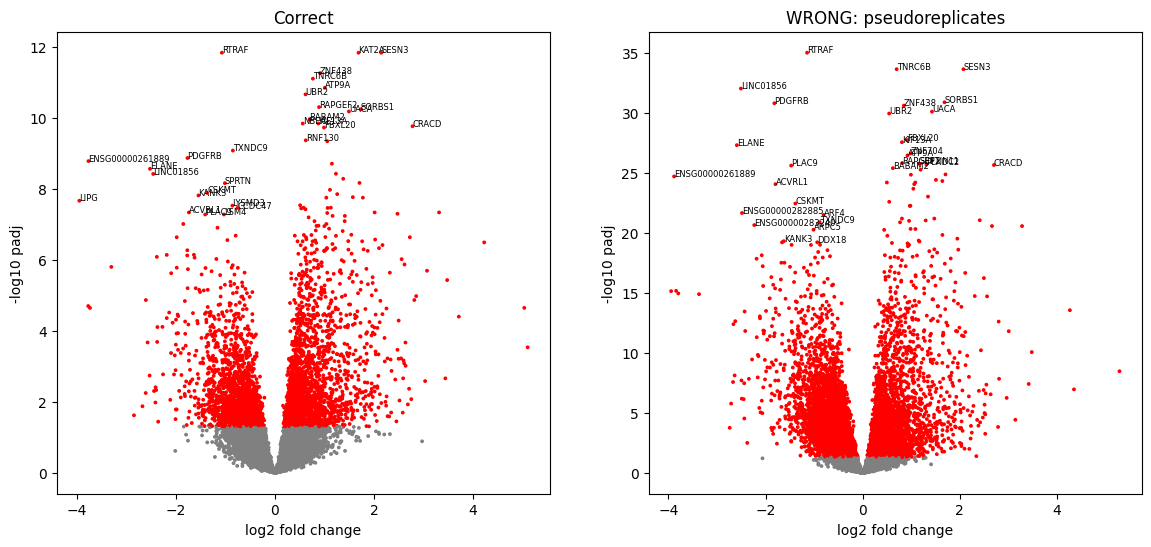

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
for ax, res, title in zip(axes, [results_with_sex_age, pseudorep_results], ["Correct", "WRONG: pseudoreplicates"]):
    res = res.dropna(subset=["padj"]).assign(y=lambda r: -np.log10(r["padj"].clip(lower=1e-300)))
    ax.scatter(res["log2FoldChange"], res["y"], s=3, c=np.where(res["padj"] < 0.05, "red", "grey"))
    top = pd.concat([res[res["log2FoldChange"] > 0].nsmallest(15, "padj"), res[res["log2FoldChange"] < 0].nsmallest(15, "padj")])
    for gene, row in top.iterrows(): ax.text(row["log2FoldChange"], row["y"], gene, fontsize=6)
    ax.set(title=title, xlabel="log2 fold change", ylabel="-log10 padj")
plt.show()

## 2. Never pool donors - Pooling donors erases variation

In [84]:
pooled_donor_table = meta[["disease"]].copy()
pooled_donor_table["pool"] = pooled_donor_table.groupby("disease").cumcount() % 3
pooled_donor_table["pool_sample"] = pooled_donor_table["disease"] + "_pool" + pooled_donor_table["pool"].astype(str)
print(pooled_donor_table["pool_sample"].value_counts())

pool_sample
DCM_pool0       15
DCM_pool1       15
DCM_pool2       14
normal_pool0     2
normal_pool1     2
normal_pool2     2
Name: count, dtype: int64


In [85]:
pooled_counts = counts.groupby(pooled_donor_table["pool_sample"]).sum()
pooled_meta = pooled_donor_table.drop_duplicates("pool_sample").set_index("pool_sample")[["disease"]].loc[pooled_counts.index]
print(pooled_meta)

             disease
pool_sample         
DCM_pool0        DCM
DCM_pool1        DCM
DCM_pool2        DCM
normal_pool0  normal
normal_pool1  normal
normal_pool2  normal


In [86]:
pooled_dds = DeseqDataSet(counts=pooled_counts, metadata=pooled_meta, design="~ disease")
pooled_dds.deseq2()
pooled_stats = DeseqStats(pooled_dds, contrast=["disease", "DCM", "normal"])
pooled_stats.summary()
pooled_results = pooled_stats.results_df

print("Correct (50 donors): ", (results_no_covariates["padj"] < 0.05).sum())
print("WRONG (6 pools):     ", (pooled_results["padj"] < 0.05).sum())

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 2.02 seconds.

Fitting dispersion trend curve...
... done in 0.21 seconds.

Fitting MAP dispersions...
... done in 1.89 seconds.

Fitting LFCs...
... done in 1.90 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                 
LINC01409         673.919990       -0.224171  0.136610 -1.640963  0.100805   
NOC2L             537.245214       -0.718947  0.187973 -3.824729  0.000131   
ENSG00000272512    96.613900       -0.685327  0.447318 -1.532079  0.125503   
HES4             1014.730573       -0.273982  0.303781 -0.901905  0.367107   
ISG15              95.518210       -0.602523  0.252895 -2.382499  0.017196   
...                      ...             ...       ...       ...       ...   
ENSG00000285444    40.871991        0.218410  0.304681  0.716848  0.473468   
ENSG00000285446    39.818580        0.286886  0.309207  0.927812  0.353505   
ENSG00000285454    33.900249       -0.125570  0.358223 -0.350536  0.725936   
C4orf36           199.920052       -0.036686  0.236442 -0.155159  0.876696   
ENSG

... done in 2.00 seconds.



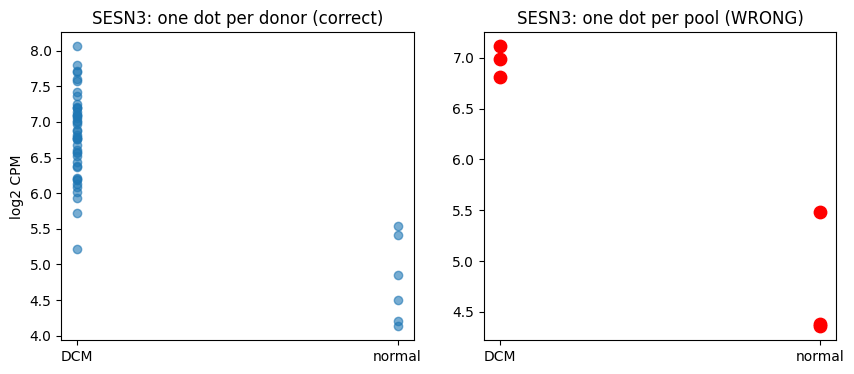

In [87]:
pooled_gene = results_no_covariates.sort_values("padj").index[0]
pooled_donor_logcpm = np.log2(counts[pooled_gene] / counts.sum(axis=1) * 1e6 + 1)
pooled_pool_logcpm = np.log2(pooled_counts[pooled_gene] / pooled_counts.sum(axis=1) * 1e6 + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
axes[0].scatter(meta["disease"], pooled_donor_logcpm.loc[meta.index], alpha=0.6)
axes[0].set(title=f"{pooled_gene}: one dot per donor (correct)", ylabel="log2 CPM")
axes[1].scatter(pooled_meta["disease"], pooled_pool_logcpm, s=80, c="red")
axes[1].set(title=f"{pooled_gene}: one dot per pool (WRONG)")
plt.show()

CPM = (gene count / total counts in the sample) × 1,000,000

## 3. Never use anything but raw counts - the wrong expression layer changes the input

In [88]:
lognorm_cells = adata_norm_dc.copy()
sc.pp.normalize_total(lognorm_cells, target_sum=1e4)
sc.pp.log1p(lognorm_cells)
print("Max value, raw .X:    ", adata_norm_dc.X[:5].max())
print("Max value, lognorm .X:", lognorm_cells.X[:5].max())

Max value, raw .X:     398.0
Max value, lognorm .X: 7.2542086


In [89]:
lognorm_pseudobulk = sc.get.aggregate(lognorm_cells, by="donor_id", func="sum")
lognorm_counts = lognorm_pseudobulk.to_df(layer="sum")
lognorm_counts.columns = lognorm_pseudobulk.var.loc[lognorm_counts.columns, "feature_name"].astype(str)
lognorm_counts = lognorm_counts.T.groupby(level=0).sum().T.loc[meta.index, counts.columns]
lognorm_counts = lognorm_counts.round().astype(int)   # rounded only so DESeq2 accepts it

print(counts.iloc[:3, :5])
print(lognorm_counts.iloc[:3, :5])

feature_name  LINC01409  NOC2L  ENSG00000272512  HES4  ISG15
DL2                  56     18                1    57      7
DL3                  74     64                0    33     10
DO1                  57     31                0    18      3
feature_name  LINC01409  NOC2L  ENSG00000272512  HES4  ISG15
DL2                  65     25                1    55     11
DL3                  88     78                0    47     13
DO1                  46     28                0    22      2


In [90]:
lognorm_dds = DeseqDataSet(counts=lognorm_counts, metadata=meta, design="~ sex + age_z + disease")
lognorm_dds.deseq2()
lognorm_stats = DeseqStats(lognorm_dds, contrast=["disease", "DCM", "normal"])
lognorm_stats.summary()
lognorm_results = lognorm_stats.results_df

print("Correct (raw counts):      ", (results_with_sex_age["padj"] < 0.05).sum())
print("WRONG (log-normalized):    ", (lognorm_results["padj"] < 0.05).sum())

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.02 seconds.

Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.
Numba: Attempted to fork from a non-m

Log2 fold change & Wald test p-value: disease DCM vs normal
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                
LINC01409        117.407727       -0.211543  0.178708 -1.183741  0.236515   
NOC2L             85.227288       -0.706842  0.189164 -3.736661  0.000186   
ENSG00000272512   14.995551       -0.920186  0.537692 -1.711364  0.087014   
HES4             161.088743       -0.261193  0.248099 -1.052776  0.292444   
ISG15             15.795570       -0.481324  0.265752 -1.811177  0.070113   
...                     ...             ...       ...       ...       ...   
ENSG00000285444    9.644196        0.403430  0.369782  1.090996  0.275275   
ENSG00000285446    8.068185        0.173471  0.362506  0.478532  0.632271   
ENSG00000285454    6.577458       -0.257702  0.349468 -0.737411  0.460872   
C4orf36           39.373103       -0.027748  0.227752 -0.121834  0.903030   
ENSG00000285471 

... done in 1.92 seconds.



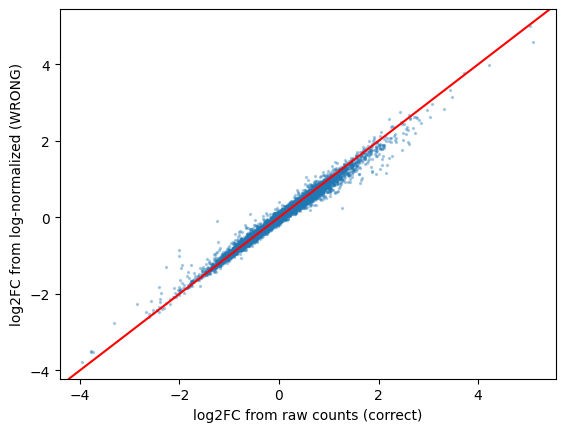

LFC correlation: 0.991


In [91]:
lognorm_lfc = pd.DataFrame({"raw": results_with_sex_age["log2FoldChange"], "lognorm": lognorm_results["log2FoldChange"]}).dropna()
plt.scatter(lognorm_lfc["raw"], lognorm_lfc["lognorm"], s=2, alpha=0.3)
plt.axline((0, 0), slope=1, color="red")
plt.xlabel("log2FC from raw counts (correct)")
plt.ylabel("log2FC from log-normalized (WRONG)")
plt.show()
print("LFC correlation:", lognorm_lfc.corr().iloc[0, 1].round(3))

In [92]:
lognorm_calls = pd.crosstab(results_with_sex_age["padj"] < 0.05, lognorm_results["padj"] < 0.05,
                            rownames=["DE with raw"], colnames=["DE with lognorm"])
print(lognorm_calls)

DE with lognorm  False  True 
DE with raw                  
False            11850    153
True               407   3301


Of 15,711 genes, **560 changed their conclusion** only because of the wrong input:

| | Genes | Meaning |
|---|---|---|
| DE in both | 3,301 | Robust |
| DE only with raw counts | 407 | Real hits **missed** by the wrong analysis |
| DE only with log-normalized | 153 | Hits that **appear** only because of the wrong input |
| DE in neither | 11,850 | Agree |

From the perspective of your correct gene list:
- **About 11% lost:** 407 of 3,708 true DE genes disappear.
- **About 4% spurious:** 153 of 3,454 wrongly-called genes weren't DE in the correct analysis.

Together that's about **1 in 7** of the DE list being different. Any downstream analysis that uses the list, such as pathway enrichment or picking candidates to validate, would be affected.

**For your notebook:** the fold changes correlate almost perfectly, yet about 560 genes change their DE call. The wrong layer doesn't break the analysis visibly, which makes it easy to miss. Always pseudobulk raw counts, and keep them in `adata.layers["counts"]` before normalizing.

## 4. Perfect confounding cannot be adjusted away

In [94]:
confounded_meta = meta[((meta["disease"] == "normal") & (meta["sex"] == "male")) |
                       ((meta["disease"] == "DCM") & (meta["sex"] == "female"))].copy()
confounded_counts = counts.loc[confounded_meta.index]
print(pd.crosstab(confounded_meta["disease"], confounded_meta["sex"]))

sex      female  male
disease              
DCM          12     0
normal        0     5


In [95]:
confounded_counts

feature_name,LINC01409,NOC2L,ENSG00000272512,HES4,ISG15,AGRN,C1orf159,SDF4,B3GALT6,UBE2J2,...,LINC02478,ENSG00000285382,ENSG00000285404,ENSG00000285407,ENSG00000285413,ENSG00000285444,ENSG00000285446,ENSG00000285454,C4orf36,ENSG00000285471
DP1,229,96,85,512,40,44,115,69,2,118,...,6,47,17,6,6,7,2,4,34,5
DP2,92,35,4,132,7,5,44,28,1,48,...,12,28,4,10,1,7,7,4,29,2
H03,113,57,16,102,16,15,55,43,2,76,...,19,32,10,5,11,6,5,1,30,0
H06,67,53,2,140,9,5,43,41,7,73,...,26,22,7,8,13,2,6,7,15,5
H21,78,106,9,79,12,10,48,77,6,78,...,8,14,9,9,19,7,15,1,24,2
H24,127,74,38,267,23,11,57,51,3,80,...,26,14,9,13,5,3,15,4,16,3
H26,17,12,2,36,1,3,17,6,1,22,...,4,5,3,2,1,4,0,2,3,0
H27,128,115,18,206,22,21,75,76,15,94,...,23,24,14,13,7,8,10,8,37,6
H34,51,26,5,53,4,3,39,17,1,32,...,6,17,9,3,1,9,5,8,18,2
H41,56,30,5,89,9,4,14,27,4,24,...,14,13,3,6,3,8,1,1,13,4


In [96]:
confounded_dds = DeseqDataSet(counts=confounded_counts, metadata=confounded_meta, design="~ disease")
confounded_dds.deseq2()
confounded_stats = DeseqStats(confounded_dds, contrast=["disease", "DCM", "normal"])
confounded_stats.summary()
confounded_results = confounded_stats.results_df

print("DE genes:", (confounded_results["padj"] < 0.05).sum())
print(confounded_results.loc[confounded_results.index.isin(sex_genes), ["log2FoldChange", "padj"]])

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 1.88 seconds.

Fitting dispersion trend curve...
... done in 0.20 seconds.

Fitting MAP dispersions...
... done in 1.94 seconds.

Fitting LFCs...
... done in 1.94 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 34 outlier genes.

Fitting dispersions...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.02 seconds.

Fitting LFCs...
... done in 0.02 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: disease DCM vs normal
                   baseMean  log2FoldChange     lfcSE      stat    pvalue  \
feature_name                                                                
LINC01409         99.976464       -0.173493  0.180980 -0.958630  0.337745   
NOC2L             69.870802       -1.004634  0.247183 -4.064328  0.000048   
ENSG00000272512   16.231011       -0.510056  0.628501 -0.811543  0.417054   
HES4             150.618670       -0.253536  0.330610 -0.766874  0.443156   
ISG15             13.522846       -0.053160  0.332858 -0.159706  0.873112   
...                     ...             ...       ...       ...       ...   
ENSG00000285444    6.809439        0.416337  0.424637  0.980454  0.326862   
ENSG00000285446    5.890319        0.406832  0.457528  0.889197  0.373897   
ENSG00000285454    4.850587       -0.099379  0.513735 -0.193444  0.846611   
C4orf36           24.200759       -0.044316  0.267360 -0.165753  0.868352   
ENSG00000285471 

... done in 1.87 seconds.



In [97]:
print("Actual (50 donors, ~ sex + age_z + disease):", (results_with_sex_age["padj"] < 0.05).sum())
print("Confounded (17 donors, ~ disease):          ", (confounded_results["padj"] < 0.05).sum())
print(pd.crosstab(results_with_sex_age["padj"] < 0.05, confounded_results["padj"] < 0.05,
                  rownames=["DE actual"], colnames=["DE confounded"]))

confounded_sex_table = pd.DataFrame({"padj_actual": results_with_sex_age["padj"],
                                     "padj_confounded": confounded_results["padj"]})
print(confounded_sex_table[confounded_sex_table.index.isin(sex_genes)])

Actual (50 donors, ~ sex + age_z + disease): 3708
Confounded (17 donors, ~ disease):           3081
DE confounded  False  True 
DE actual                  
False          11434    569
True            1196   2512
              padj_actual  padj_confounded
feature_name                              
TSIX             0.824552     3.008654e-12
XIST             0.130230     5.512253e-36
KDM5D            0.329813     8.426387e-22
DDX3Y            0.915910     1.139151e-22
USP9Y            0.016636     4.298954e-75
RPS4Y1           0.170713     9.776335e-41
UTY              0.022239    1.238457e-104
EIF1AY           0.579771     3.012751e-15


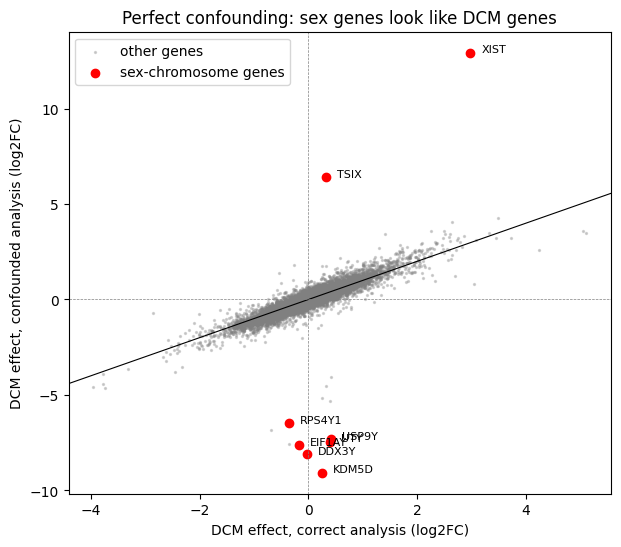

In [99]:
confounded_lfc = pd.DataFrame({"actual": results_with_sex_age["log2FoldChange"],
                               "confounded": confounded_results["log2FoldChange"]}).dropna()
confounded_sex_points = confounded_lfc[confounded_lfc.index.isin(sex_genes)]

plt.figure(figsize=(7, 6))
plt.scatter(confounded_lfc["actual"], confounded_lfc["confounded"], s=2, alpha=0.3, c="grey", label="other genes")
plt.scatter(confounded_sex_points["actual"], confounded_sex_points["confounded"], c="red", label="sex-chromosome genes")
for gene, row in confounded_sex_points.iterrows():
    plt.annotate(gene, (row["actual"], row["confounded"]), xytext=(8, 0), textcoords="offset points", fontsize=8)
plt.axline((0, 0), slope=1, color="black", lw=0.8)
plt.axhline(0, color="grey", lw=0.5, ls="--")
plt.axvline(0, color="grey", lw=0.5, ls="--")
plt.xlabel("DCM effect, correct analysis (log2FC)")
plt.ylabel("DCM effect, confounded analysis (log2FC)")
plt.title("Perfect confounding: sex genes look like DCM genes")
plt.legend()
plt.show()

The Y-chromosome genes (RPS4Y1, DDX3Y, KDM5D, UTY, USP9Y, EIF1AY) sit near 0 in the actual analysis but at −6 to −9 in the confounded subset. That's a 64- to 500-fold "decrease in DCM" that is entirely a sex effect: every normal donor in the subset is a man, and no DCM donor is.

TSIX shows the same pattern in the other direction: about 0 in the actual analysis, about +6.5 when confounded.

The grey cloud of all other genes still follows the diagonal. So confounding doesn't distort everything; it creates large false effects in the genes the confounder controls. That's why it's dangerous: most results look reasonable, and the false ones are mixed in among them.

XIST is worth a closer look. It's at +13 when confounded, which is expected, but it's also about +3 in your actual adjusted model. After adjusting for sex, XIST should be close to 0. A likely reason is that your normal group has only 1 woman. The model learns how XIST differs between women and men mostly from the DCM donors, and the comparison of normal vs. DCM women relies on that single person. So the sex adjustment is weak in exactly the genes where sex matters most. Another possibility is that tiny XIST counts in men make the fold change unstable.

## 5. Never ignore pairing

In [100]:
# Unpaired
# dds = DeseqDataSet(counts=counts, metadata=meta, design="~ sex + age_z + disease")

#Paired
# dds = DeseqDataSet(counts=counts, metadata=meta, design="~ donor_id + condition")

Would you add sex and age in the paired design? or is it even required?

It's not required: in a paired design, every donor is compared with themselves. Donor H16 before treatment and H16 after treatment have the same sex and the same age. So sex and age can't create a difference between the two conditions; they're identical on both sides of the comparison.

## 6. Have enough replicates i.e, have  enough Donors not a higher cell count

In [101]:
replication_cells_per_donor = adata_norm_dc.obs["donor_id"].astype(str).value_counts()
replication_one_dcm = replication_cells_per_donor[meta.index[meta["disease"] == "DCM"]].idxmax()
replication_one_normal = replication_cells_per_donor[meta.index[meta["disease"] == "normal"]].idxmax()
print("Nuclei:", replication_cells_per_donor[[replication_one_dcm, replication_one_normal]].to_dict())

replication_donors_1v1 = [replication_one_dcm, replication_one_normal]
try:
    replication_dds_1v1 = DeseqDataSet(counts=counts.loc[replication_donors_1v1], metadata=meta.loc[replication_donors_1v1], design="~ disease")
    replication_dds_1v1.deseq2()
    replication_stats_1v1 = DeseqStats(replication_dds_1v1, contrast=["disease", "DCM", "normal"])
    replication_stats_1v1.summary()
    print("DE genes (1 vs 1):", (replication_stats_1v1.results_df["padj"] < 0.05).sum())
except Exception as error:
    print("Failed:", error)

Nuclei: {'H40': 2385, 'H51': 2379}
Using None as control genes, passed at DeseqDataSet initialization
Failed: The number of samples and the number of design variables are equal, i.e., there are no replicates to estimate the dispersion. Please use a design with fewer variables.


Fitting size factors...
... done in 0.02 seconds.



In [102]:
replication_rng = np.random.default_rng(0)
replication_normal_donors = meta.index[meta["disease"] == "normal"]
replication_dcm_donors = meta.index[meta["disease"] == "DCM"]
replication_reference = set(results_no_covariates.index[results_no_covariates["padj"] < 0.05])
replication_summary = []

for n in [2, 3, 4, 5, 6]:
    replication_donors = list(replication_rng.choice(replication_normal_donors, n, replace=False)) + \
                         list(replication_rng.choice(replication_dcm_donors, n, replace=False))
    replication_counts = counts.loc[replication_donors]
    replication_counts = replication_counts.loc[:, replication_counts.sum() > 0]
    replication_dds = DeseqDataSet(counts=replication_counts, metadata=meta.loc[replication_donors], design="~ disease", quiet=True)
    replication_dds.deseq2()
    replication_stats = DeseqStats(replication_dds, contrast=["disease", "DCM", "normal"], quiet=True)
    replication_stats.summary()
    replication_found = set(replication_stats.results_df.index[replication_stats.results_df["padj"] < 0.05])
    replication_summary.append({
        "donors per group": n,
        "DE genes": len(replication_found),
        "% of full-data DE found": round(100 * len(replication_found & replication_reference) / len(replication_reference), 1),
        "median lfcSE": round(replication_stats.results_df["lfcSE"].median(), 3),
    })

replication_summary = pd.DataFrame(replication_summary)
print(replication_summary)

   donors per group  DE genes  % of full-data DE found  median lfcSE
0                 2        56                      1.0         0.577
1                 3        90                      2.0         0.395
2                 4       555                     12.9         0.372
3                 5       884                     20.2         0.369
4                 6      1736                     38.4         0.271


The trend is clear and matches your notebook message.

**Real hits found (vs. the full-data result):**

| Donors per group | DE genes | % of full-data hits found |
|---|---|---|
| 2 | 56 | 1% |
| 3 | 90 | 2% |
| 4 | 555 | 13% |
| 5 | 884 | 20% |
| 6 | 1,736 | 38% |

- **2–3 per group:** almost nothing. At 3, the "practical starting target", you find only **2%** of what the full data shows. It's analyzable, but very weak.
- **4–6 per group:** detection rises steeply, and every added donor matters.
- **Even at 6 vs. 6** you find only 38%. The full analysis (6 normal vs. 44 DCM) finds far more, because the extra DCM donors add power. The full data has the same 44 + 6 donors as before; nothing about the cells changed, only how many people the model learns from.

# What Not To Do - After the Results

## 7. Understand correct DESeq2 result meaning - Dont get confused with up/downregulated conditions

explain_gene = results_with_sex_age.sort_values("padj").index[0]
explain_row = results_with_sex_age.loc[explain_gene]
print(explain_gene)
print(explain_row)

| Column | Meaning |
|---|---|
| `baseMean` | Average **normalized** count across **all samples in the analysis** (DCM and normal together), not per group |
| `log2FoldChange` | DCM vs. normal from the **model**, adjusted for sex and age. +1 = 2× higher in DCM, −1 = 2× lower |
| `lfcSE` | Uncertainty of that fold change. Smaller means more precise |
| `stat` | Wald statistic = log2FoldChange ÷ lfcSE, i.e. how many standard errors away from 0 |
| `pvalue` | Raw p-value for that one gene |
| `padj` | Adjusted p-value (Benjamini–Hochberg), corrected for testing thousands of genes. Use this one |

## 8. Understand the y-axis in Volcano plot

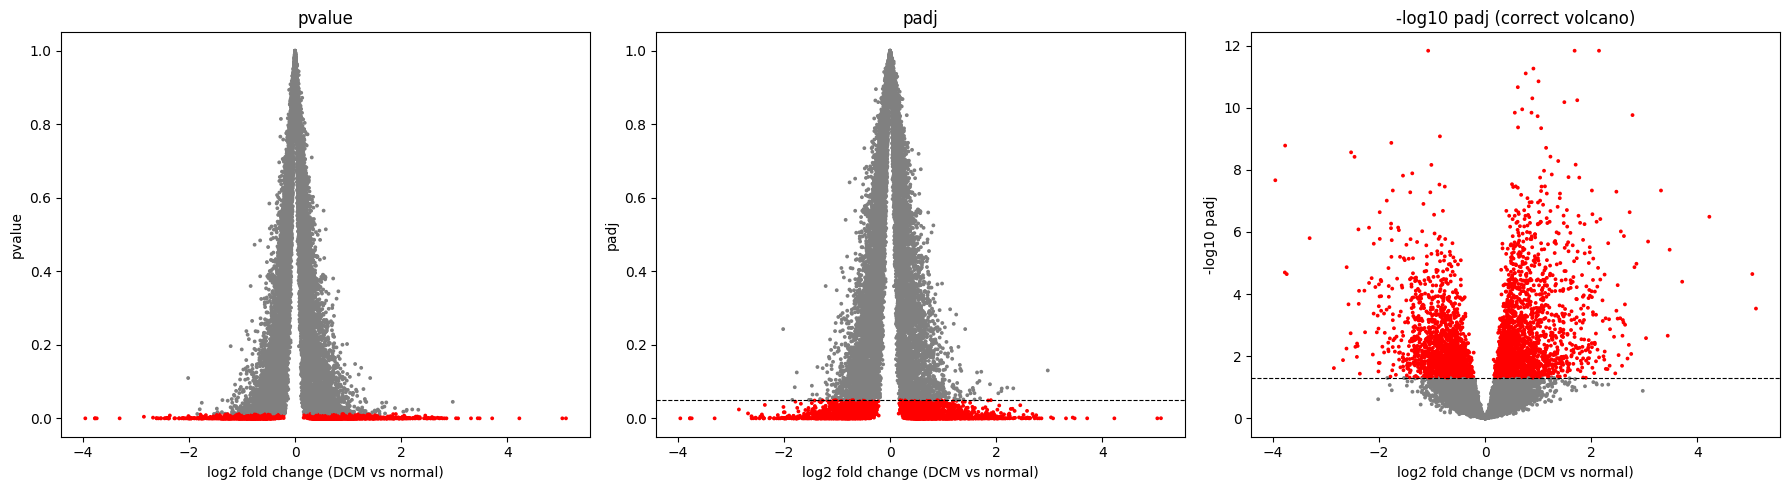

In [111]:
volcano_res = results_with_sex_age.dropna(subset=["padj"])
volcano_colors = np.where(volcano_res["padj"] < 0.05, "red", "grey")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(volcano_res["log2FoldChange"], volcano_res["pvalue"], s=3, c=volcano_colors)
axes[0].set(title="pvalue", ylabel="pvalue")

axes[1].scatter(volcano_res["log2FoldChange"], volcano_res["padj"], s=3, c=volcano_colors)
axes[1].axhline(0.05, ls="--", c="black", lw=0.8)
axes[1].set(title="padj", ylabel="padj")

axes[2].scatter(volcano_res["log2FoldChange"], -np.log10(volcano_res["padj"].clip(lower=1e-300)), s=3, c=volcano_colors)
axes[2].axhline(-np.log10(0.05), ls="--", c="black", lw=0.8)
axes[2].set(title="-log10 padj (correct volcano)", ylabel="-log10 padj")

for ax in axes: ax.set_xlabel("log2 fold change (DCM vs normal)")
plt.tight_layout()
plt.show()

## 9. Shrink logFC

In [112]:
shrink_meta = meta.copy()
shrink_meta["disease"] = pd.Categorical(shrink_meta["disease"], categories=["normal", "DCM"])

shrink_dds = DeseqDataSet(counts=counts, metadata=shrink_meta, design="~ sex + age_z + disease", quiet=True)
shrink_dds.deseq2()
shrink_stats = DeseqStats(shrink_dds, contrast=["disease", "DCM", "normal"], quiet=True)
shrink_stats.summary()
shrink_unshrunk = shrink_stats.results_df.copy()

print(shrink_dds.varm["LFC"].columns.tolist())
shrink_stats.lfc_shrink(coeff="disease[T.DCM]")
shrink_shrunk = shrink_stats.results_df.copy()

['Intercept', 'sex[T.male]', 'age_z', 'disease[T.DCM]']


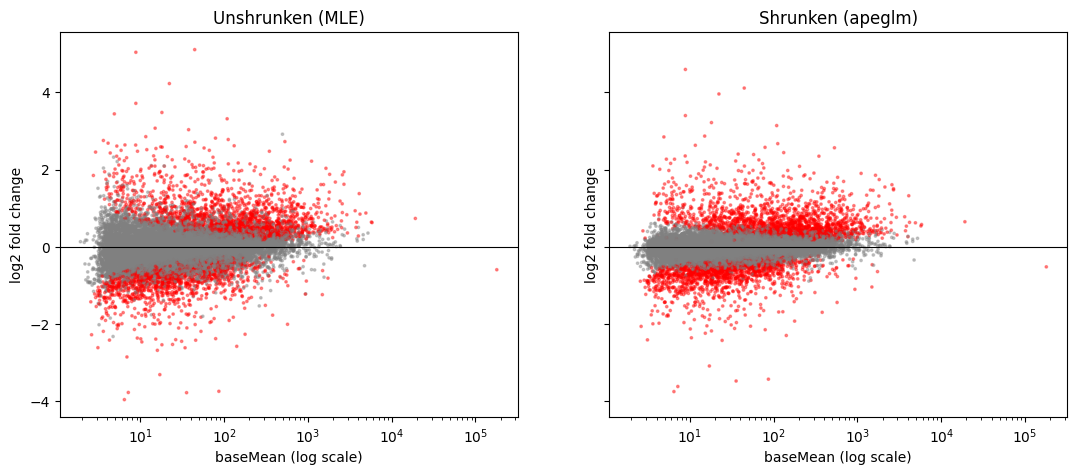

In [113]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, res, title in zip(axes, [shrink_unshrunk, shrink_shrunk], ["Unshrunken (MLE)", "Shrunken (apeglm)"]):
    ax.scatter(res["baseMean"], res["log2FoldChange"], s=3, alpha=0.4, c=np.where(res["padj"] < 0.05, "red", "grey"))
    ax.set_xscale("log")
    ax.axhline(0, c="black", lw=0.8)
    ax.set(title=title, xlabel="baseMean (log scale)", ylabel="log2 fold change")
plt.show()

## 10. Every top gene needs a donor-level view - One donor can dominate the average.

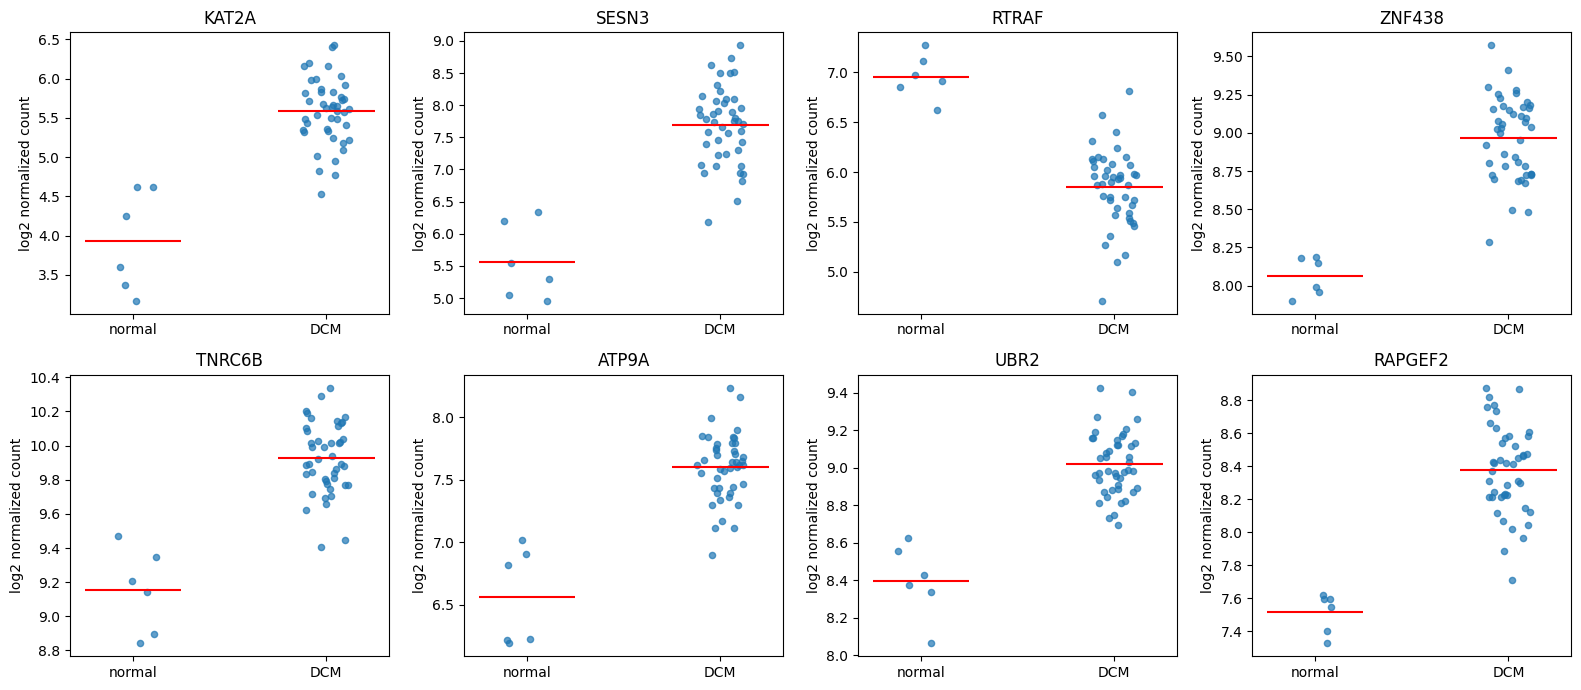

In [115]:
donorview_norm = dds_with_sex_age.to_df().div(dds_with_sex_age.obs["size_factors"], axis=0)
donorview_disease = meta.loc[donorview_norm.index, "disease"]
donorview_top = results_with_sex_age.sort_values("padj").index[:8]
donorview_rng = np.random.default_rng(0)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, gene in zip(axes.ravel(), donorview_top):
    x = (donorview_disease == "DCM").astype(int) + donorview_rng.uniform(-0.12, 0.12, len(donorview_disease))
    y = np.log2(donorview_norm[gene] + 1)
    ax.scatter(x, y, s=20, alpha=0.7)
    for pos, group in enumerate(["normal", "DCM"]):
        ax.hlines(y[donorview_disease == group].mean(), pos - 0.25, pos + 0.25, color="red")
    ax.set(xticks=[0, 1], xticklabels=["normal", "DCM"], title=gene, ylabel="log2 normalized count")
plt.tight_layout()
plt.show()

## 11. Statistical significance is not biological importance and a high logFC is not a proven effect.

In [116]:
effect_res = results_with_sex_age.dropna(subset=["padj"])
effect_cols = ["baseMean", "log2FoldChange", "lfcSE", "padj"]

effect_small_sig = effect_res[(effect_res["padj"] < 0.05) & (effect_res["log2FoldChange"].abs() < 0.3)]
effect_large_unsure = effect_res[(effect_res["padj"] >= 0.05) & (effect_res["log2FoldChange"].abs() > 1)]

print("Significant but small  (|log2FC| < 0.3, under 1.23x):", len(effect_small_sig))
print(effect_small_sig.sort_values("padj")[effect_cols].head(5))
print("\nLarge but not significant (|log2FC| > 1, over 2x):", len(effect_large_unsure))
print(effect_large_unsure.sort_values("log2FoldChange", key=abs, ascending=False)[effect_cols].head(5))

Significant but small  (|log2FC| < 0.3, under 1.23x): 179
                baseMean  log2FoldChange     lfcSE      padj
feature_name                                                
RALGAPA1      581.845648        0.281313  0.067567  0.000616
ZFYVE9        244.216964        0.290801  0.070232  0.000665
KMT2C         792.121587        0.272443  0.068526  0.001156
MICU2         297.447393        0.266626  0.068143  0.001416
SPPL2A        193.863102        0.281760  0.073135  0.001707

Large but not significant (|log2FC| > 1, over 2x): 128
                baseMean  log2FoldChange     lfcSE      padj
feature_name                                                
XIST          496.378114        2.972510  1.482093  0.130230
LINC01446       4.778137        2.322484  1.024342  0.081584
CBLN1           5.269992        2.208090  0.979562  0.083664
COMP           13.412949        2.104833  0.927126  0.081100
LINC02008      19.156660        2.096626  0.904046  0.073953


A gene's logFC being above 2× is not proof that it really changes above 2×. With few donors, almost nothing can be proven to change that much.

The common practice of padj < 0.05 plus |logFC| > 1